In [1]:
from feature_extraction import run_extraction, extract_all_features
from model import SVM, KNN, save_model, load_model
from config import (KERNEL, C, GAMMA, K, SEED, DURATIONS, FOLDER_PATH, TEST_SNR, TEST_COMPRESSION, DOWN_SR)
from evaluation import (grid_search, search_best_duration, evaluate_models, plot_robustness, show_table, show_confusion_grid)
from preprocessing import prepare_data, load_dataset, split_data, SPLITS
import numpy as np
from tqdm import tqdm
import pandas as pd

from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

In [2]:
original_dataset = dict(zip(SPLITS, split_data(load_dataset(FOLDER_PATH))))
original_features = extract_all_features(original_dataset["train"], desc="Extract Original Train Data")

Loading: 100%|██████████| 236/236 [00:02<00:00, 81.93it/s] 


Using saved split from C:\Users\bayub\Documents\percussion_classification\split.csv
Train data: 188
	daluo distribution: 40
	bangu distribution: 47
	xiaoluo distribution: 52
	naobo distribution: 49
Test data: 48
	daluo distribution: 10
	bangu distribution: 12
	xiaoluo distribution: 13
	naobo distribution: 13


Extract Original Train Data: 100%|██████████| 188/188 [00:15<00:00, 12.13it/s]


In [3]:
SVM_params, _ = grid_search(
    {"kernel": KERNEL, "C": C, "gamma": GAMMA},
    SVM,
    X= original_features.X, y= original_features.labels, 
    excludes=[(("kernel", "gamma"), ("linear", "scale"))],  # gamma has no effect on the linear kernel
    random_state=SEED
)

searching for the best hyperparameter combination:   3%|▎         | 1/36 [00:24<14:10, 24.31s/it]

new best params: {'kernel': 'linear', 'C': 0.1, 'gamma': 'scale'}
new best accuracy: 0.8677098150782362


searching for the best hyperparameter combination:  36%|███▌      | 13/36 [02:48<02:31,  6.61s/it]

new best params: {'kernel': 'poly', 'C': 10, 'gamma': 'scale'}
new best accuracy: 0.9630156472261735


searching for the best hyperparameter combination:  47%|████▋     | 17/36 [03:29<02:27,  7.77s/it]

new best params: {'kernel': 'poly', 'C': 100, 'gamma': 'scale'}
new best accuracy: 0.9893314366998578


searching for the best hyperparameter combination: 100%|██████████| 36/36 [04:24<00:00,  7.35s/it]


In [4]:
KNN_params, _ = grid_search(
    {"k": K},
    KNN,
    X= original_features.X, y= original_features.labels
)

searching for the best hyperparameter combination:  17%|█▋        | 1/6 [00:00<00:01,  4.07it/s]

new best params: {'k': 1}
new best accuracy: 0.9732574679943102


searching for the best hyperparameter combination: 100%|██████████| 6/6 [00:01<00:00,  4.29it/s]


In [5]:
svm_best_duration, svm_durations = search_best_duration(DURATIONS, SVM(random_state=SEED, **SVM_params), original_dataset["train"])

100%|██████████| 5/5 [01:09<00:00, 13.90s/it]

The best duration is: 1.5, with accuracy: 1.0


In [6]:
knn_best_duration, knn_durations = search_best_duration(DURATIONS, KNN(**KNN_params), original_dataset["train"])

100%|██████████| 5/5 [00:44<00:00,  8.84s/it]

The best duration is: 0.5, with accuracy: 0.9947368421052631


In [7]:
print (svm_durations)
print (knn_durations)

accuracy_mean = {}
best_accuracy = 0
for key in svm_durations.keys():
    accuracy_mean[key] = (svm_durations[key] + knn_durations [key])/2

print(accuracy_mean)

best_duration, best_accuracy = max(accuracy_mean.items(), key=lambda item: item[1])

print(f"The best overall duration is {best_duration}s, with accuracy mean of {best_accuracy}")



{0.5: np.float64(0.9947368421052631), 1.0: np.float64(0.9947368421052631), 1.5: np.float64(1.0), 2.0: np.float64(0.9945945945945945), 2.5: np.float64(0.9893314366998578)}
{0.5: np.float64(0.9947368421052631), 1.0: np.float64(0.9893314366998578), 1.5: np.float64(0.9893314366998578), 2.0: np.float64(0.9893314366998578), 2.5: np.float64(0.9840682788051209)}
{0.5: np.float64(0.9947368421052631), 1.0: np.float64(0.9920341394025605), 1.5: np.float64(0.9946657183499289), 2.0: np.float64(0.9919630156472261), 2.5: np.float64(0.9866998577524894)}
The best overall duration is 0.5s, with accuracy mean of 0.9947368421052631


In [8]:
train, test = prepare_data(max_duration=best_duration)
data = {
    "train":train,
    "test": test,
}

# original, noise, mp3, downsample
original, noise, mp3, downsample = run_extraction(False, data)

testing = {
    "original": original["test"],
    "noise": noise["test"],
    "mp3": mp3["test"],
    "downsample": downsample["test"]
}

scenarios = {
    "original":              [original["train"]],
    "noise":                 [noise["train"]],
    "mp3":                   [mp3["train"]],
    "downsample":            [downsample["train"]],
    "original+noise":        [original["train"], noise["train"]],
    "original+mp3":          [original["train"], mp3["train"]],
    "original+noise+mp3":    [original["train"], noise["train"], mp3["train"]],
    "all":                   [original["train"], noise["train"], mp3["train"], downsample["train"]],
}

Loading: 100%|██████████| 236/236 [00:00<00:00, 1240.44it/s]


Using saved split from C:\Users\bayub\Documents\percussion_classification\split.csv
Train data: 188
	daluo distribution: 40
	bangu distribution: 47
	xiaoluo distribution: 52
	naobo distribution: 49
Test data: 48
	daluo distribution: 10
	bangu distribution: 12
	xiaoluo distribution: 13
	naobo distribution: 13


downsample (test): 100%|██████████| 48/48 [00:02<00:00, 18.51it/s]


Wrote 2456 entries to C:\Users\bayub\Documents\percussion_classification\augmented_dataset\manifest.csv


downsample 8000 (test): 100%|██████████| 48/48 [00:00<00:00, 52.35it/s]


In [9]:
svm_models = []
for scenario, data in tqdm(scenarios.items(), "Train SVM model for each scenario"):
    X_train = np.concatenate([part.X for part in data])
    y_train = np.concatenate([part.labels for part in data])

    svm_model = SVM(random_state=SEED, **SVM_params).fit(X_train, y_train)
    save_model(svm_model, (scenario+"_svm"))
    svm_models.append(svm_model)

Train SVM model for each scenario:  12%|█▎        | 1/8 [00:00<00:05,  1.36it/s]

model saved to C:\Users\bayub\Documents\percussion_classification\models\original_svm.pkl


Train SVM model for each scenario:  25%|██▌       | 2/8 [00:03<00:11,  1.94s/it]

model saved to C:\Users\bayub\Documents\percussion_classification\models\noise_svm.pkl


Train SVM model for each scenario:  38%|███▊      | 3/8 [00:10<00:20,  4.04s/it]

...

model saved to C:\Users\bayub\Documents\percussion_classification\models\original+mp3_svm.pkl


Train SVM model for each scenario:  88%|████████▊ | 7/8 [00:54<00:11, 11.24s/it]

model saved to C:\Users\bayub\Documents\percussion_classification\models\original+noise+mp3_svm.pkl


Train SVM model for each scenario: 100%|██████████| 8/8 [01:36<00:00, 12.07s/it]

model saved to C:\Users\bayub\Documents\percussion_classification\models\all_svm.pkl


In [10]:
knn_models = []
for scenario, data in tqdm(scenarios.items(), "Train KNN model for each scenario"):
    X_train = np.concatenate([part.X for part in data])
    y_train = np.concatenate([part.labels for part in data])

    knn_model = KNN(**KNN_params).fit(X_train, y_train)
    save_model(knn_model, (scenario+"_knn"))
    knn_models.append(knn_model)

Train KNN model for each scenario: 100%|██████████| 8/8 [00:00<00:00, 531.04it/s]

model saved to C:\Users\bayub\Documents\percussion_classification\models\original_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\noise_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\mp3_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\downsample_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\original+noise_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\original+mp3_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\original+noise+mp3_knn.pkl
model saved to C:\Users\bayub\Documents\percussion_classification\models\all_knn.pkl


Testing KNN models: 100%|██████████| 8/8 [00:15<00:00,  1.93s/it]


## SVM

test set,original,noise 30,noise 20,noise 10,noise 5,noise 0,mp3 2,mp3 5,mp3 9,downsample 22050,downsample 16000,downsample 8000
train,,,,,,,,,,,,
original,1.00,0.87,0.48,0.33,0.23,0.11,0.81,0.54,0.45,0.35,0.31,0.22
noise,0.95,1.00,1.00,0.87,0.50,0.30,0.46,0.33,0.57,0.28,0.30,0.10
mp3,0.62,0.17,0.10,0.10,0.10,0.10,1.00,1.00,0.98,0.95,0.98,0.29
downsample,0.10,0.10,0.10,0.10,0.10,0.10,0.19,0.19,0.30,1.00,1.00,1.00
original+noise,1.00,1.00,1.00,0.87,0.51,0.33,0.91,0.82,0.73,0.35,0.63,0.10
original+mp3,0.98,0.98,0.77,0.23,0.15,0.11,1.00,1.00,1.00,0.78,0.73,0.19
original+noise+mp3,1.00,1.00,1.00,0.71,0.23,0.11,1.00,1.00,1.00,0.94,0.85,0.19
all,1.00,1.00,1.00,0.46,0.25,0.11,1.00,1.00,1.00,1.00,1.00,1.00


test set,original,noise 30,noise 20,noise 10,noise 5,noise 0,mp3 2,mp3 5,mp3 9,downsample 22050,downsample 16000,downsample 8000
train,,,,,,,,,,,,
original,1.00,0.90,0.60,0.48,0.35,0.27,0.81,0.58,0.48,0.48,0.40,0.31
noise,0.96,1.00,1.00,0.88,0.58,0.44,0.48,0.42,0.60,0.38,0.42,0.25
mp3,0.65,0.29,0.25,0.25,0.25,0.25,1.00,1.00,0.98,0.96,0.98,0.35
downsample,0.25,0.25,0.25,0.25,0.25,0.25,0.29,0.29,0.35,1.00,1.00,1.00
original+noise,1.00,1.00,1.00,0.88,0.60,0.50,0.92,0.83,0.75,0.48,0.67,0.25
original+mp3,0.98,0.98,0.77,0.35,0.29,0.27,1.00,1.00,1.00,0.79,0.75,0.29
original+noise+mp3,1.00,1.00,1.00,0.71,0.35,0.27,1.00,1.00,1.00,0.94,0.85,0.29
all,1.00,1.00,1.00,0.56,0.38,0.27,1.00,1.00,1.00,1.00,1.00,1.00


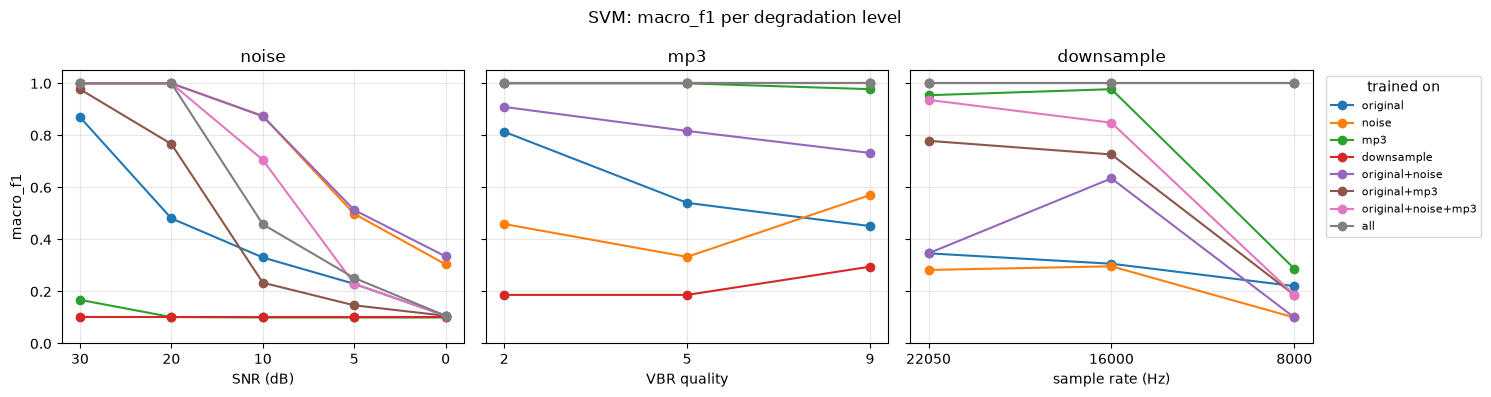

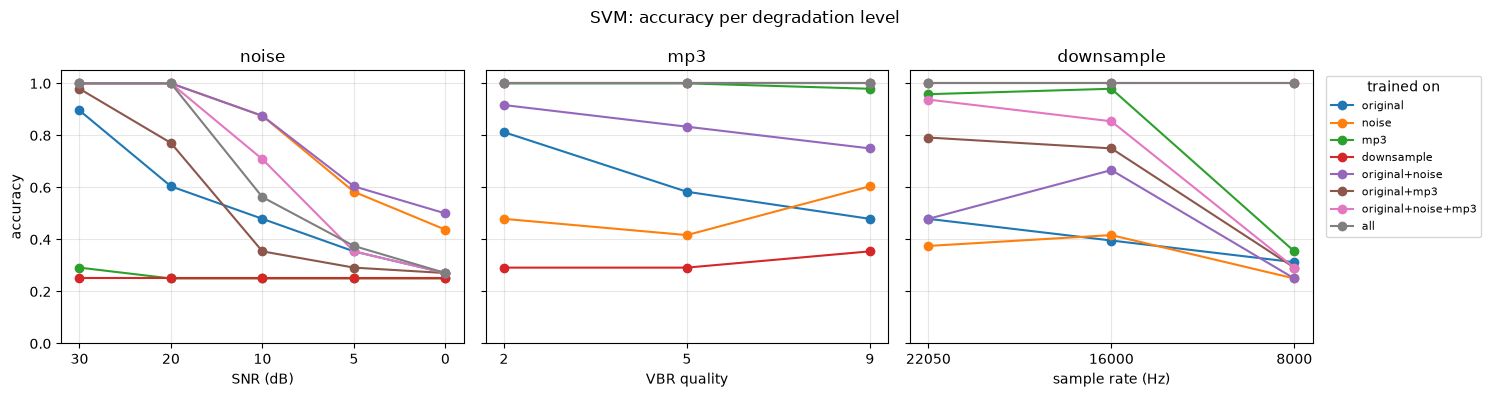

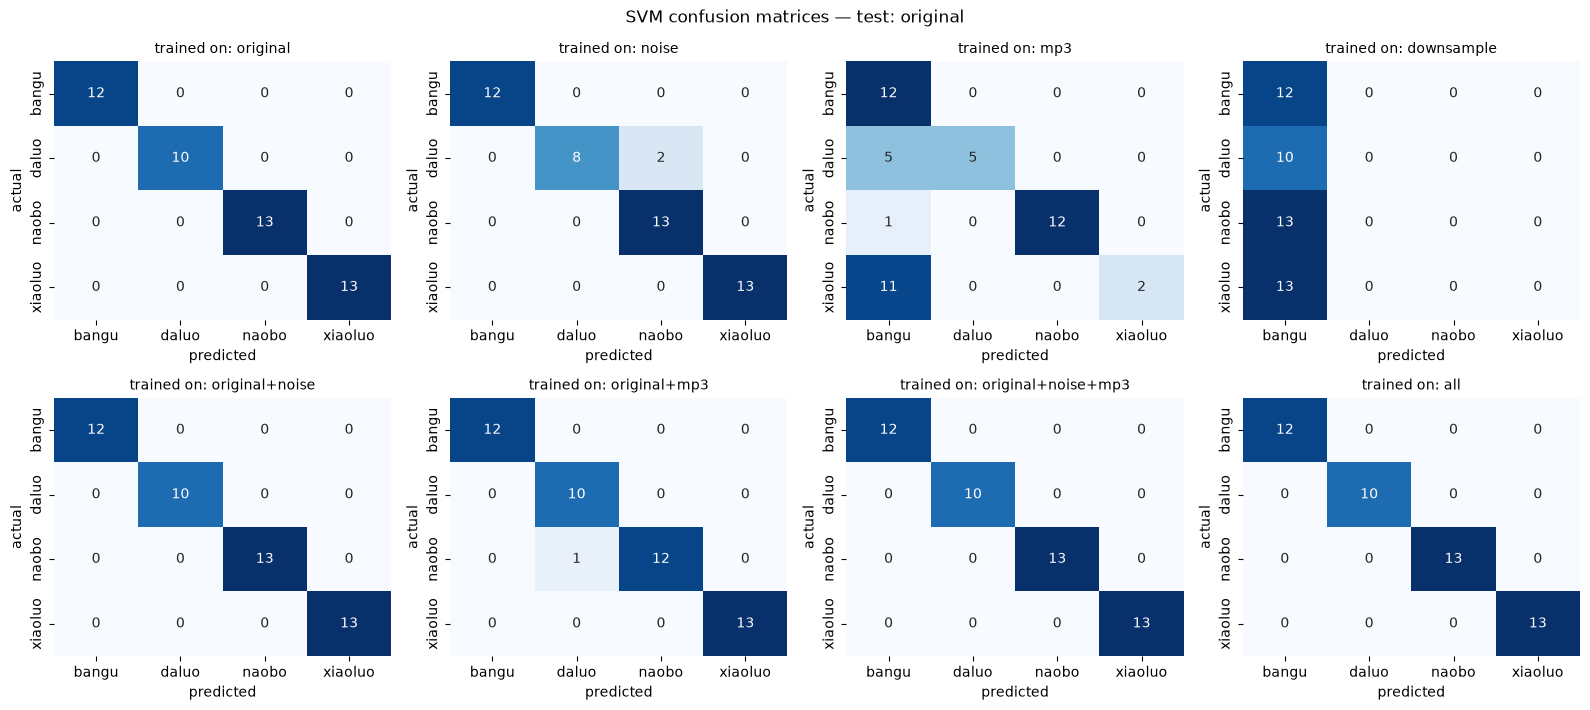

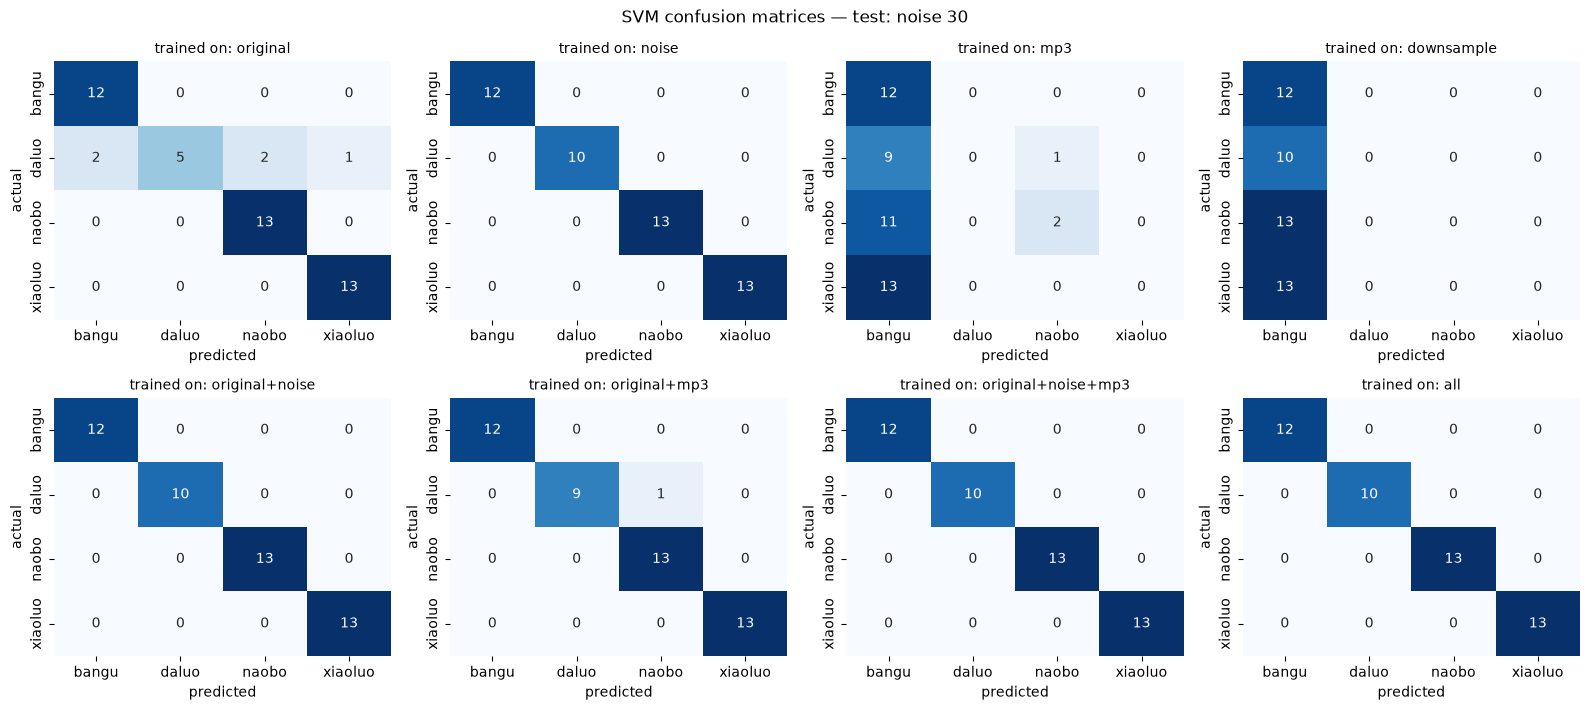

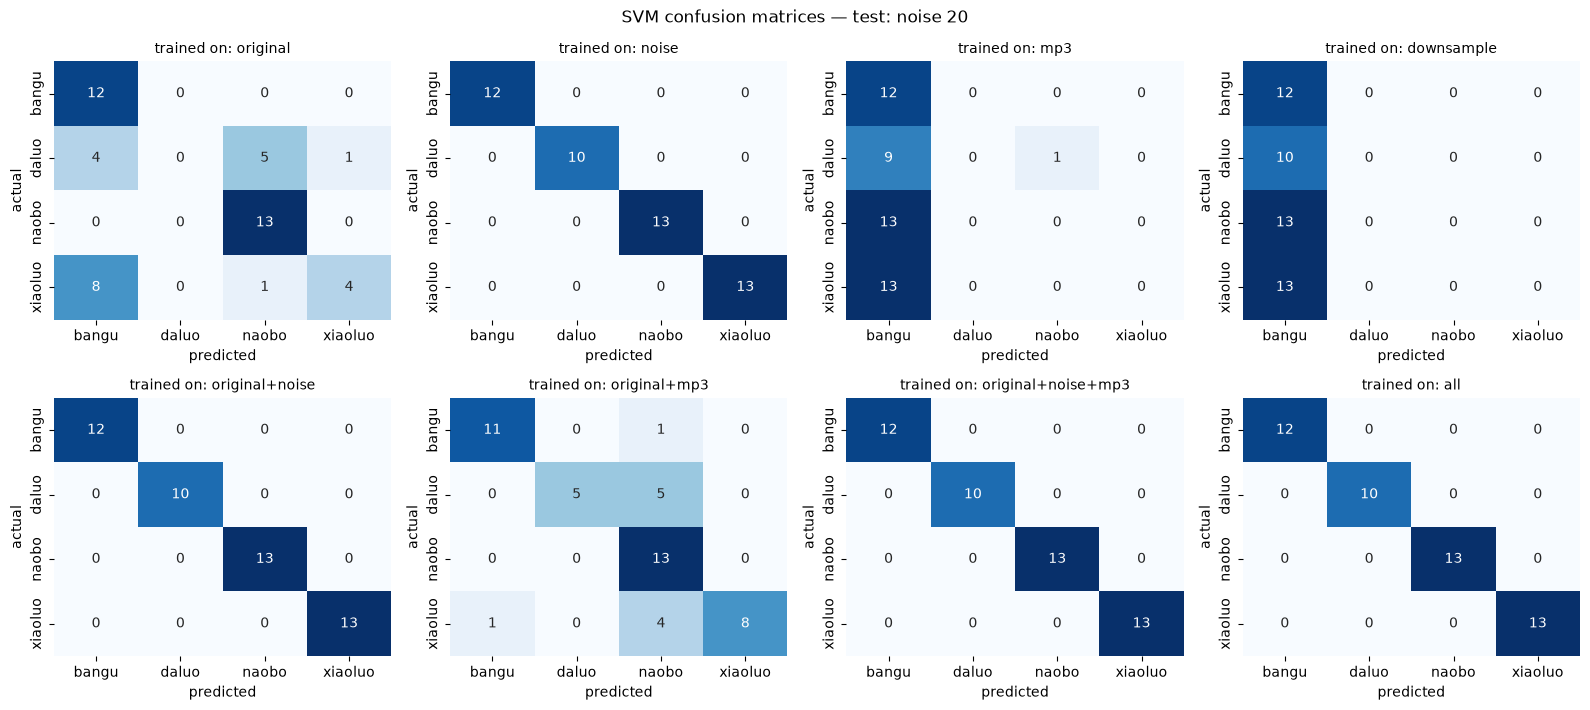

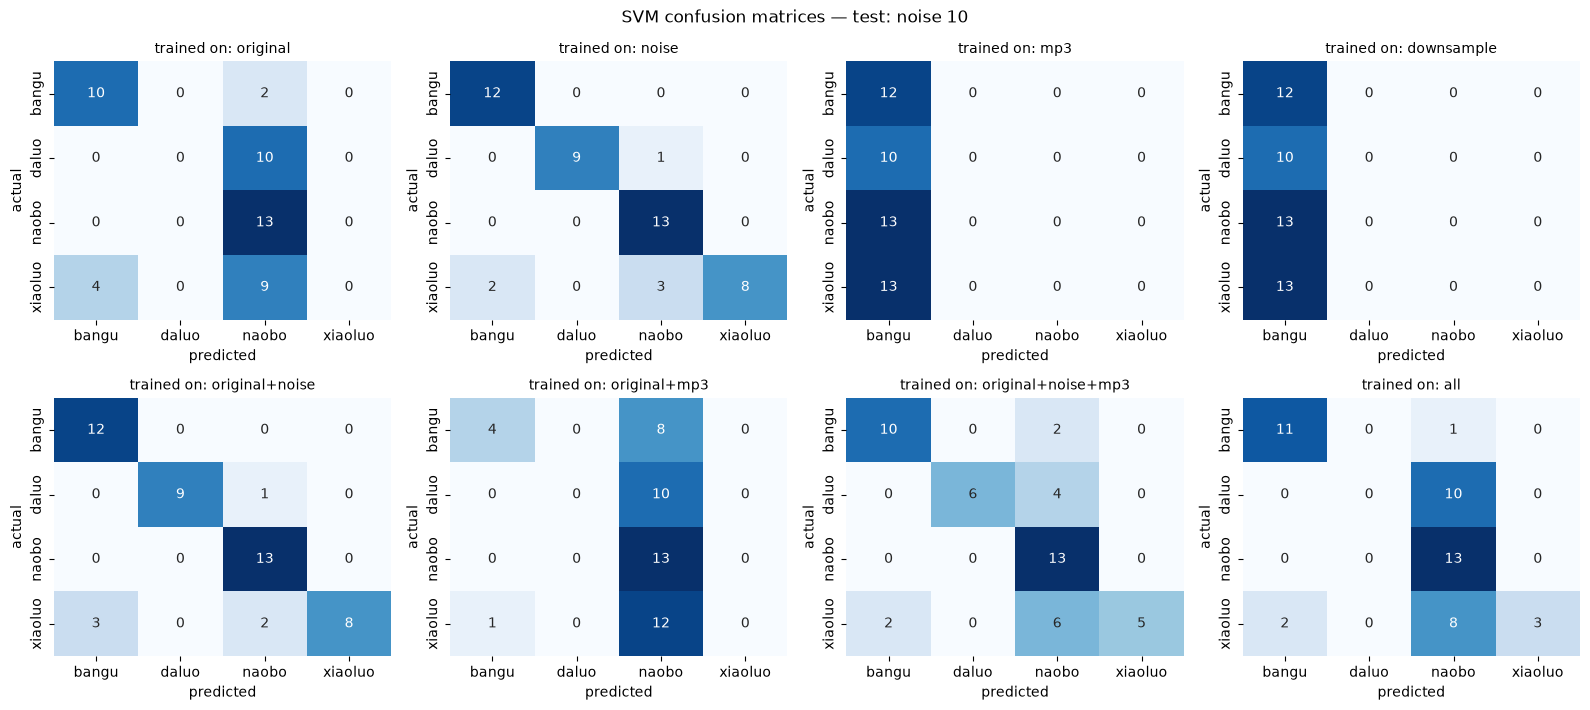

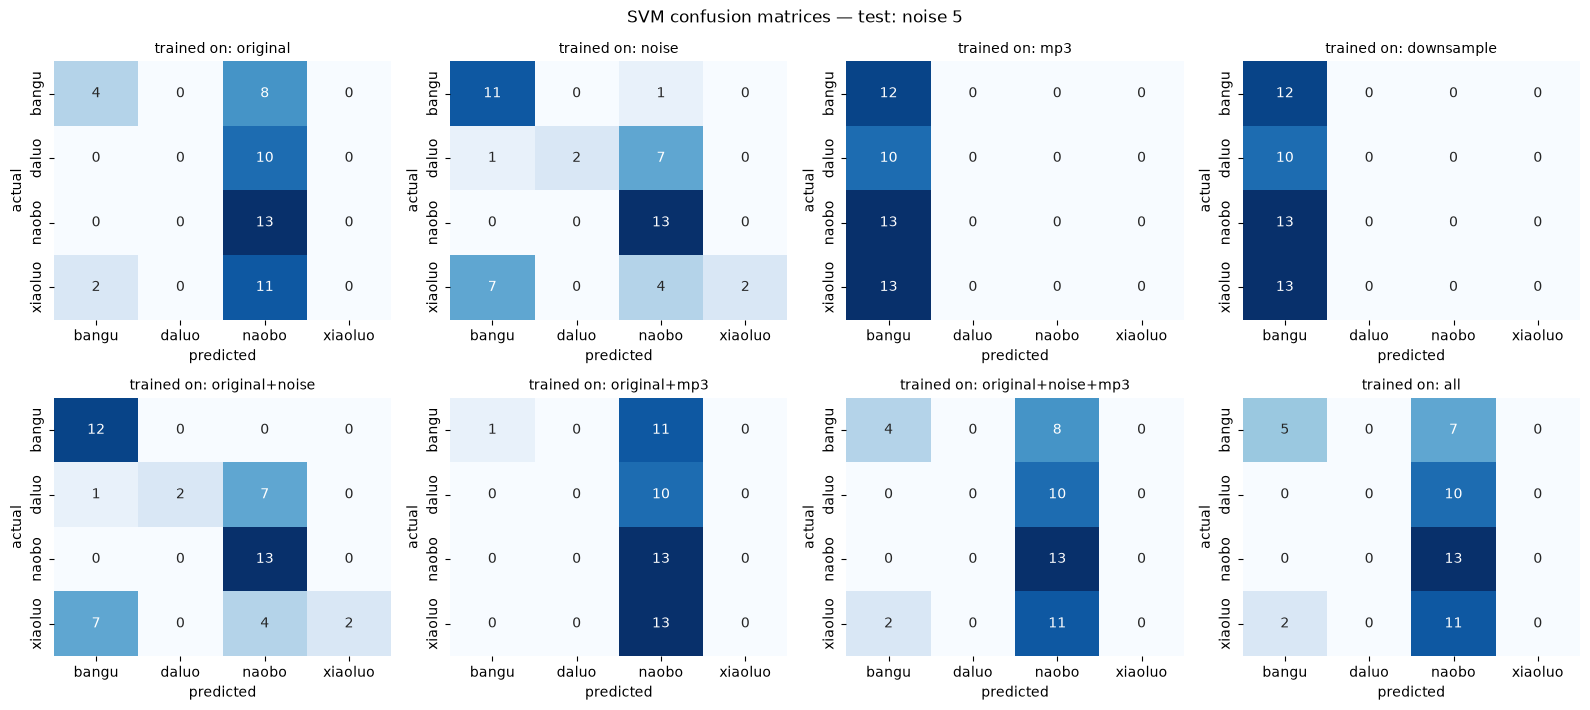

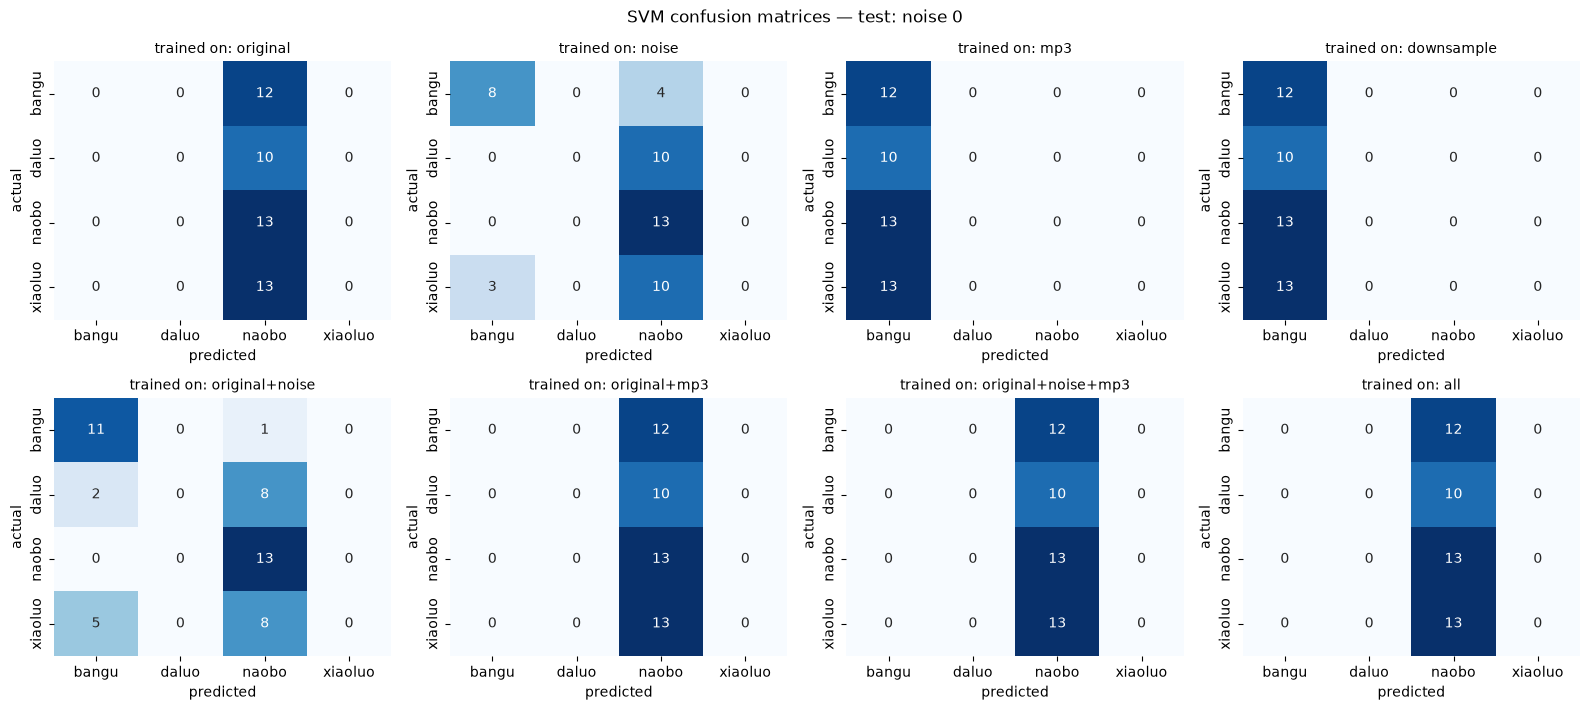

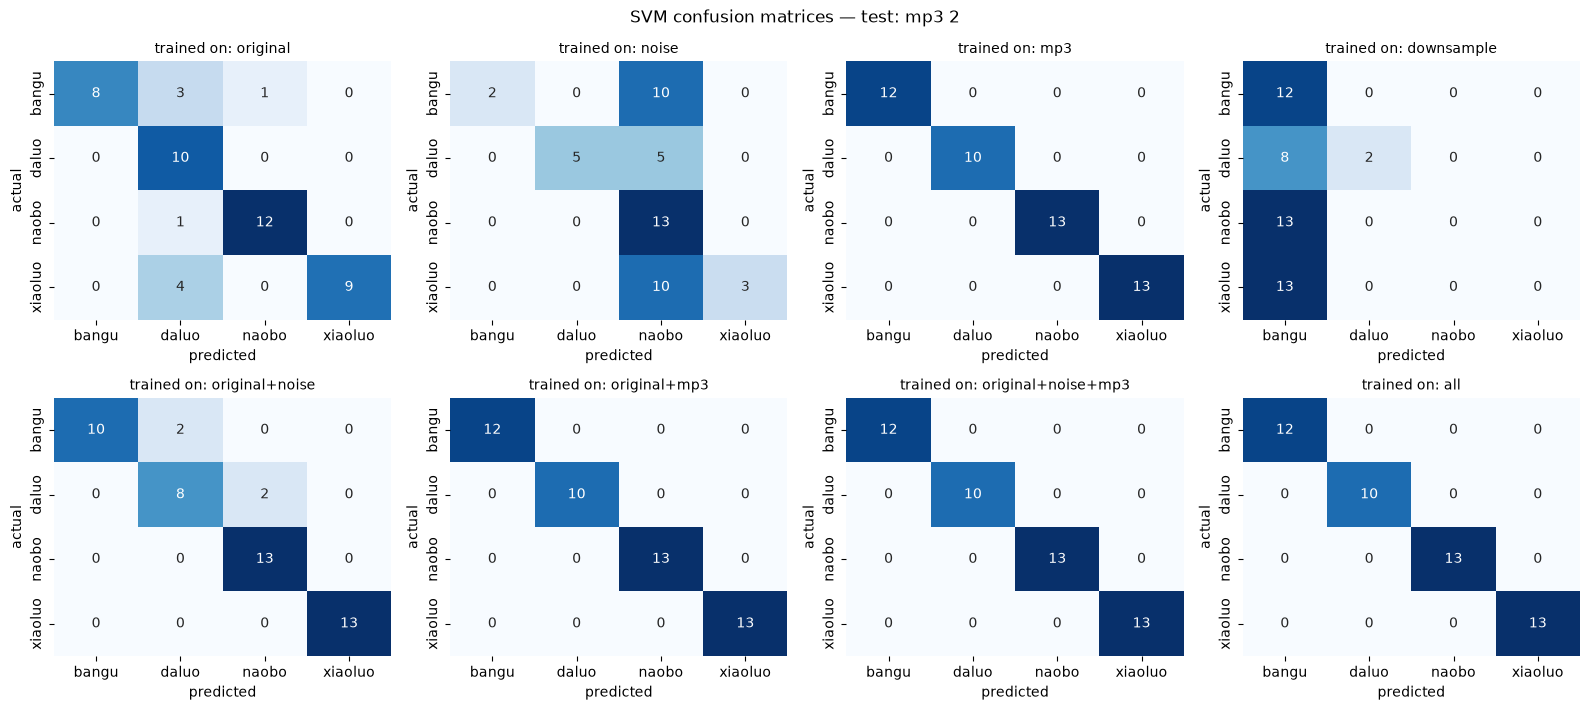

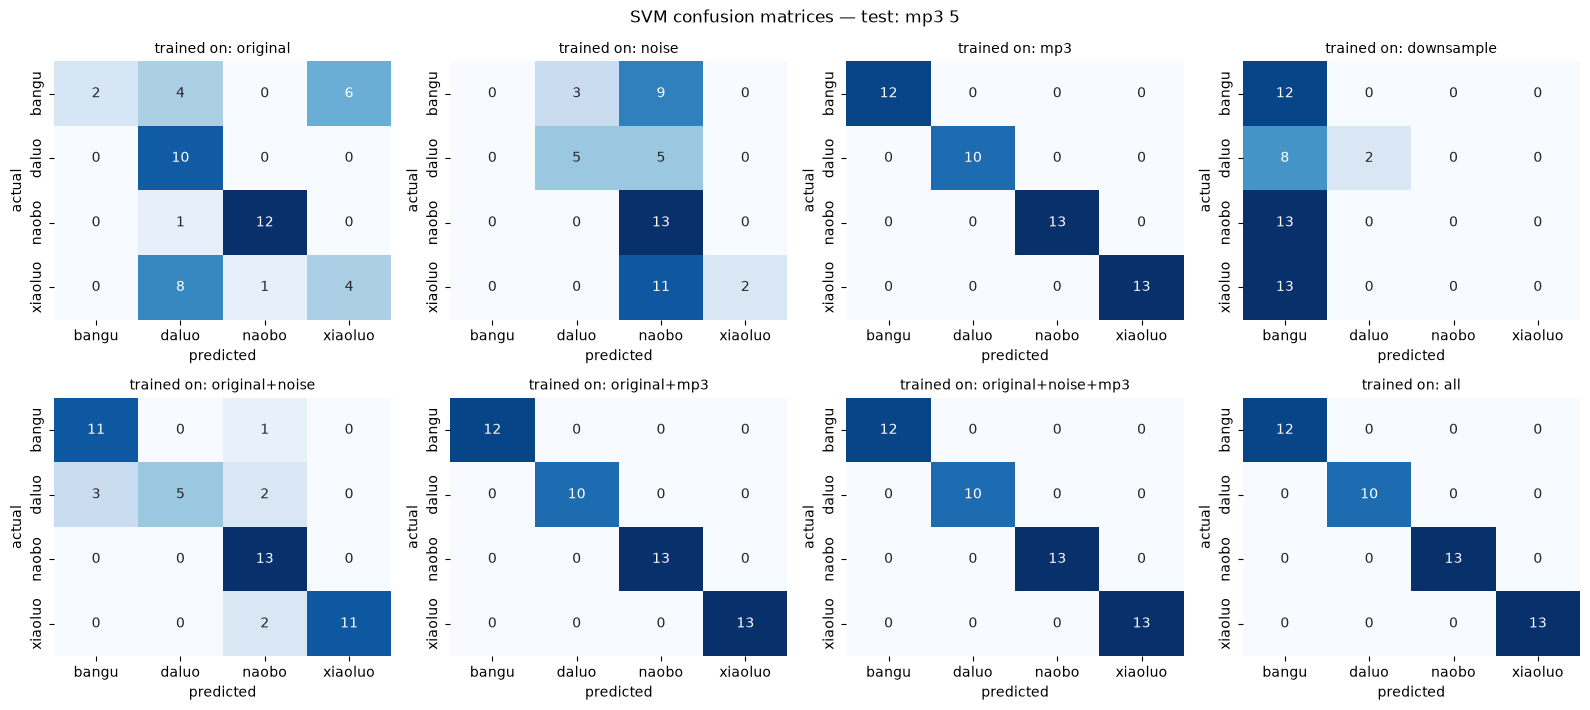

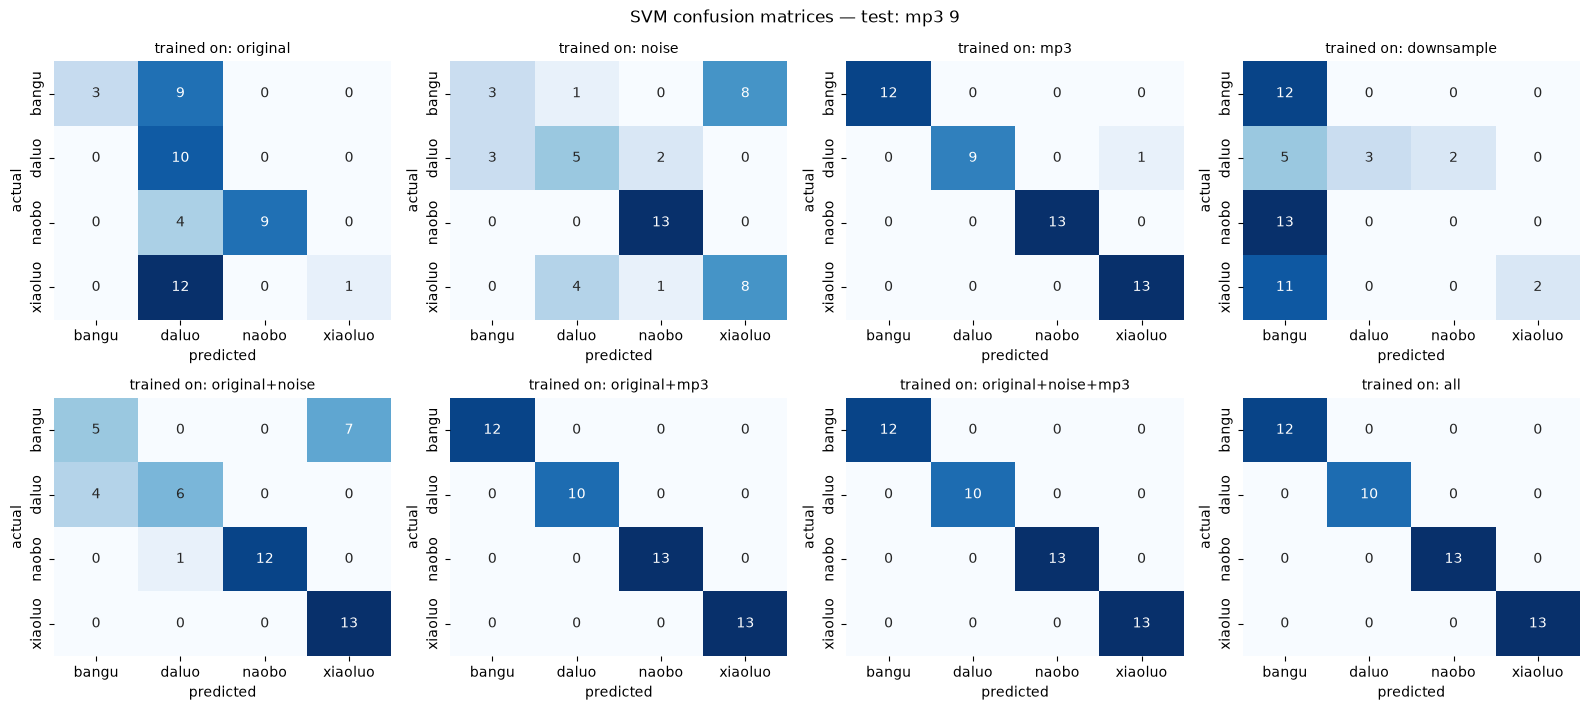

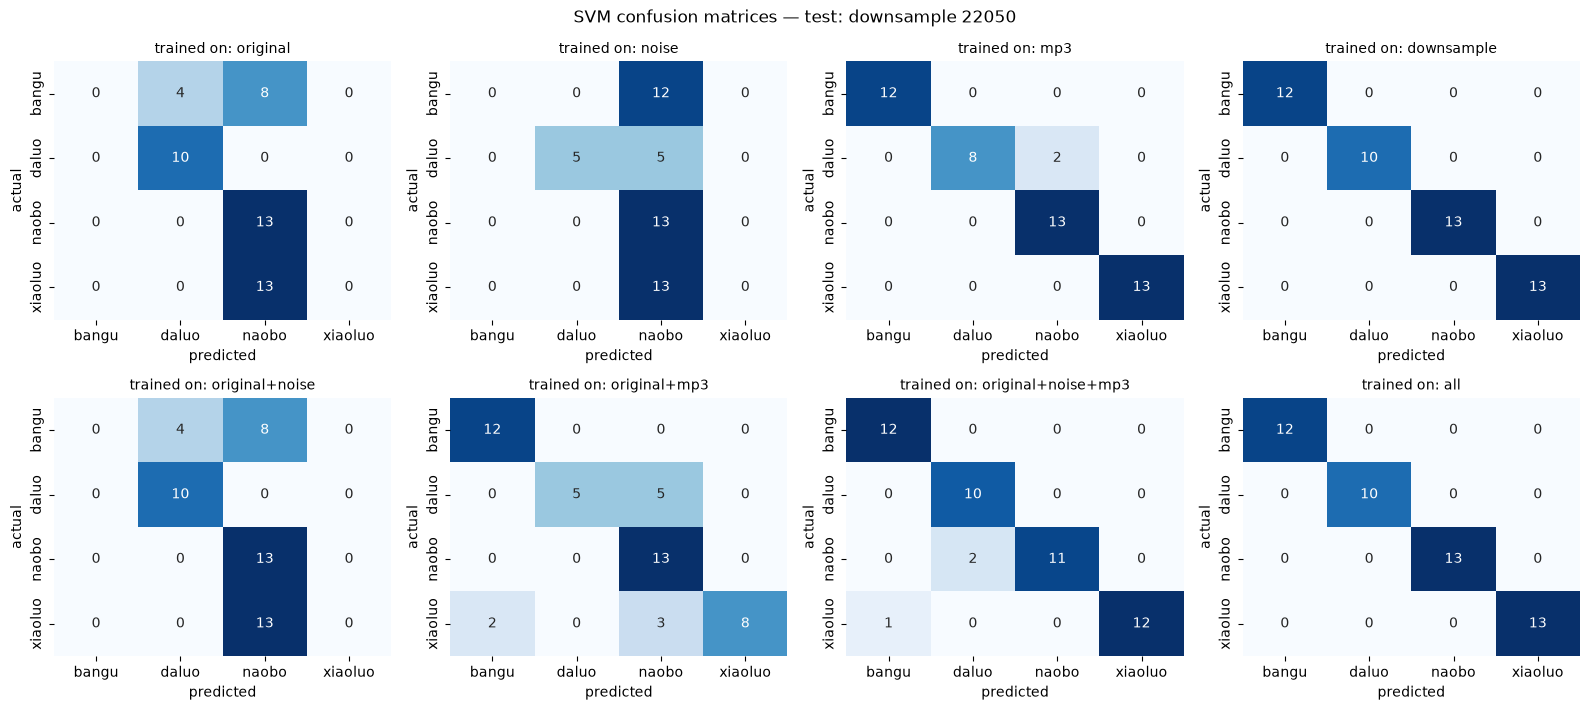

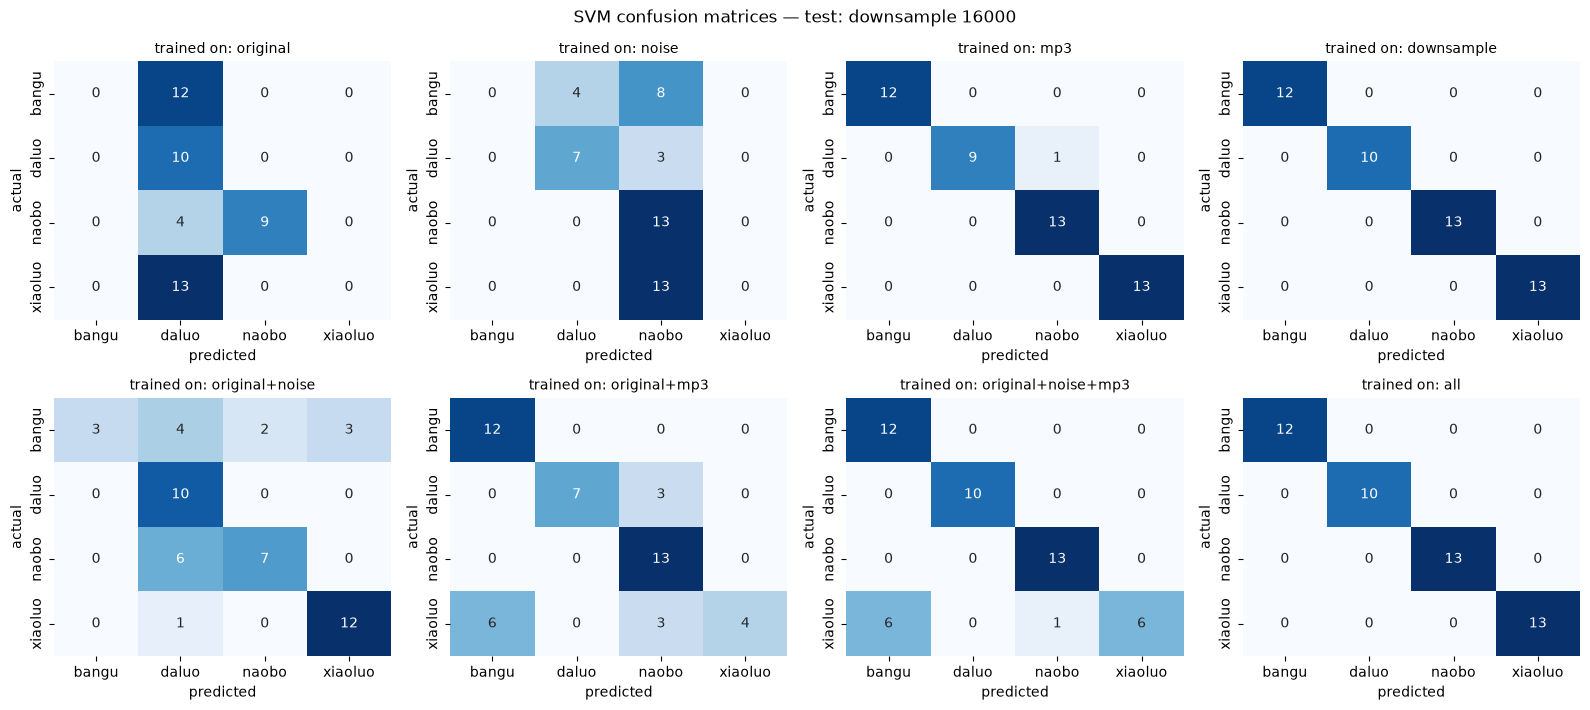

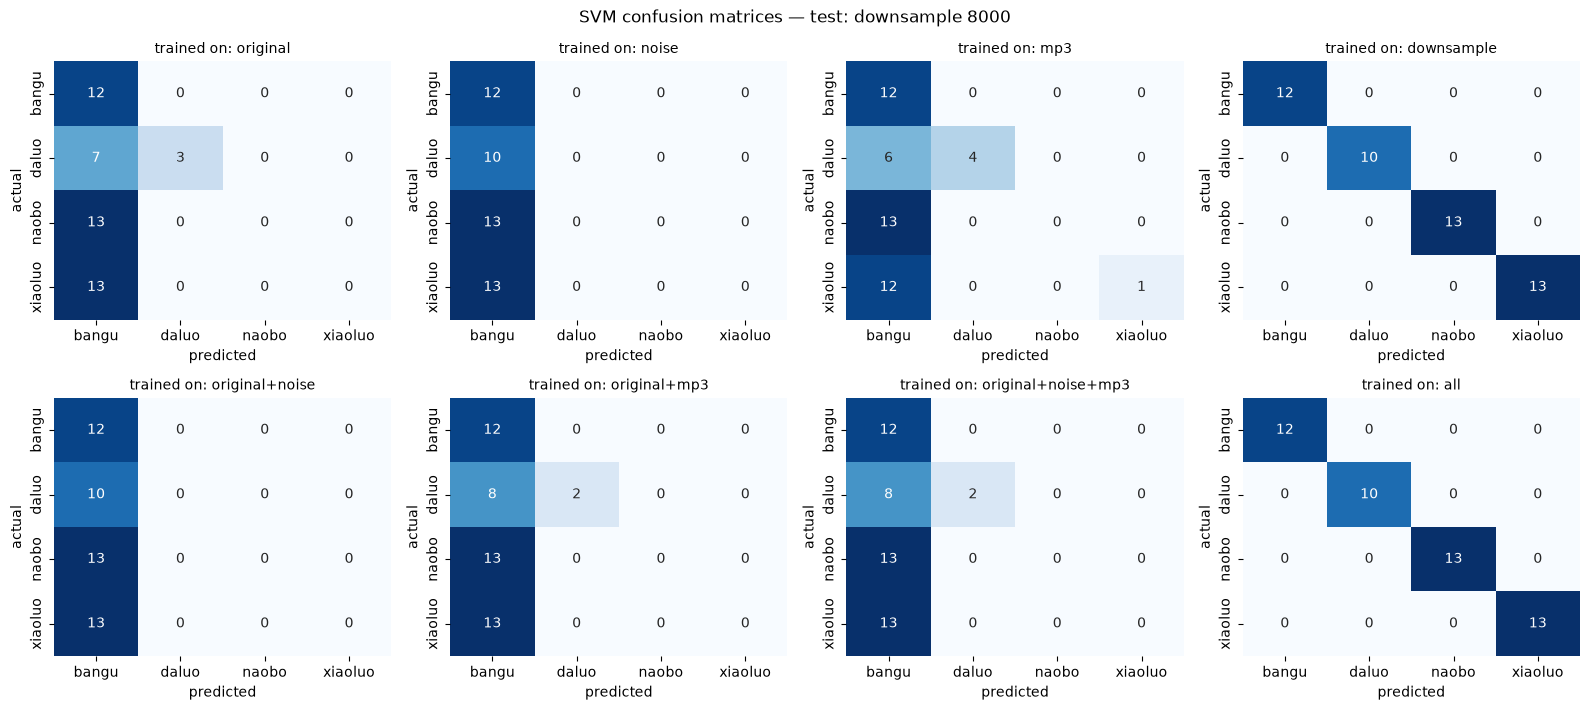

## KNN

test set,original,noise 30,noise 20,noise 10,noise 5,noise 0,mp3 2,mp3 5,mp3 9,downsample 22050,downsample 16000,downsample 8000
train,,,,,,,,,,,,
original,1.00,0.85,0.46,0.12,0.11,0.11,0.81,0.73,0.26,0.39,0.24,0.30
noise,1.00,1.00,1.00,0.80,0.27,0.22,1.00,0.96,0.28,0.78,0.24,0.09
mp3,0.93,0.66,0.45,0.15,0.11,0.11,1.00,1.00,0.98,0.70,0.75,0.31
downsample,0.10,0.10,0.10,0.10,0.10,0.10,0.29,0.39,0.90,1.00,1.00,1.00
original+noise,1.00,1.00,1.00,0.80,0.27,0.22,0.81,0.73,0.26,0.39,0.24,0.30
original+mp3,1.00,0.85,0.46,0.12,0.11,0.11,1.00,1.00,0.98,0.70,0.75,0.31
original+noise+mp3,1.00,1.00,1.00,0.80,0.27,0.22,1.00,1.00,0.98,0.70,0.75,0.31
all,1.00,1.00,1.00,0.80,0.27,0.22,1.00,1.00,0.98,1.00,1.00,1.00


test set,original,noise 30,noise 20,noise 10,noise 5,noise 0,mp3 2,mp3 5,mp3 9,downsample 22050,downsample 16000,downsample 8000
train,,,,,,,,,,,,
original,1.00,0.88,0.56,0.27,0.27,0.27,0.81,0.73,0.33,0.42,0.31,0.38
noise,1.00,1.00,1.00,0.81,0.38,0.35,1.00,0.96,0.35,0.77,0.31,0.21
mp3,0.94,0.75,0.56,0.29,0.27,0.27,1.00,1.00,0.98,0.71,0.75,0.42
downsample,0.25,0.25,0.25,0.25,0.25,0.25,0.35,0.48,0.92,1.00,1.00,1.00
original+noise,1.00,1.00,1.00,0.81,0.38,0.35,0.81,0.73,0.33,0.42,0.31,0.38
original+mp3,1.00,0.88,0.56,0.27,0.27,0.27,1.00,1.00,0.98,0.71,0.75,0.42
original+noise+mp3,1.00,1.00,1.00,0.81,0.38,0.35,1.00,1.00,0.98,0.71,0.75,0.42
all,1.00,1.00,1.00,0.81,0.38,0.35,1.00,1.00,0.98,1.00,1.00,1.00


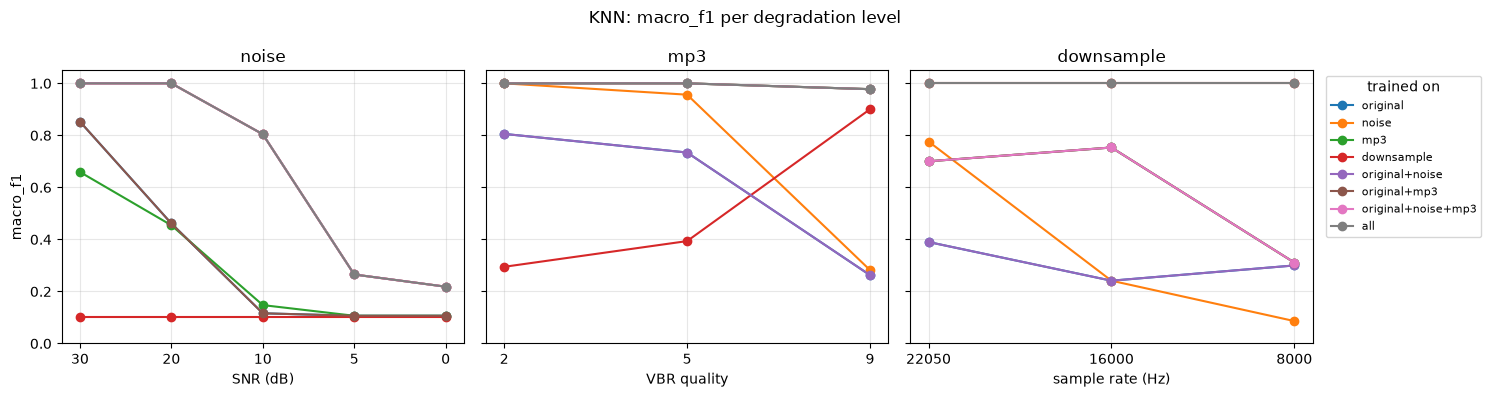

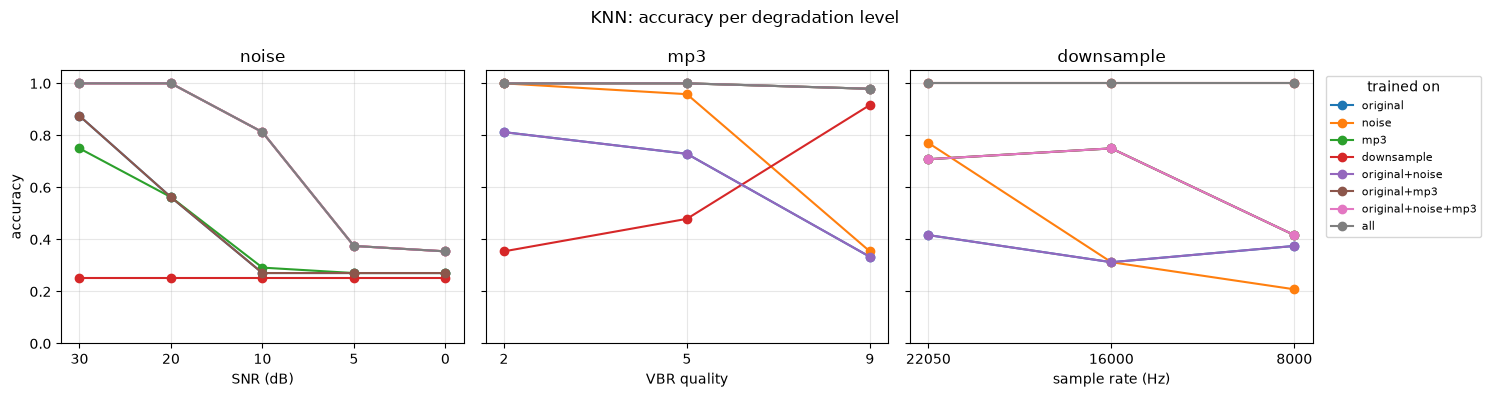

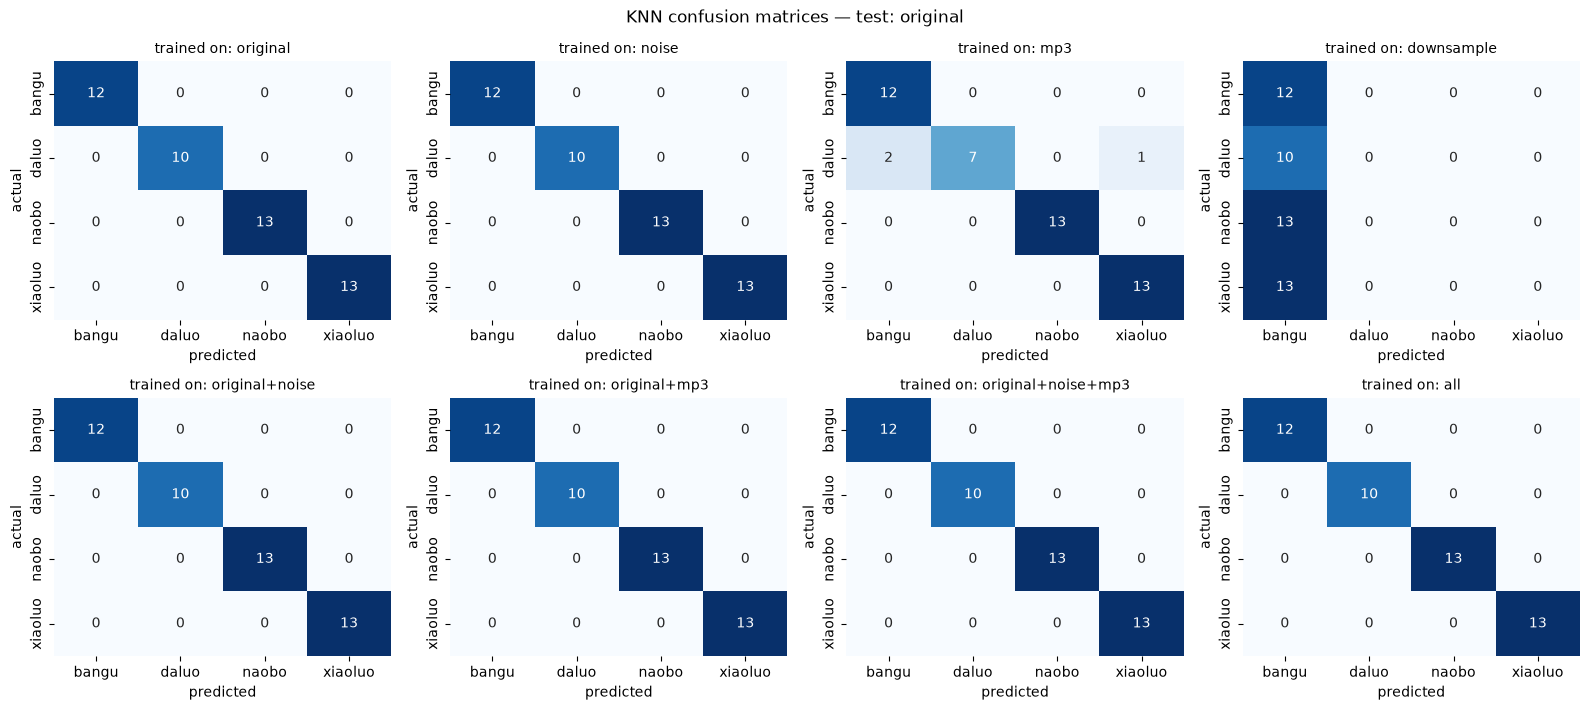

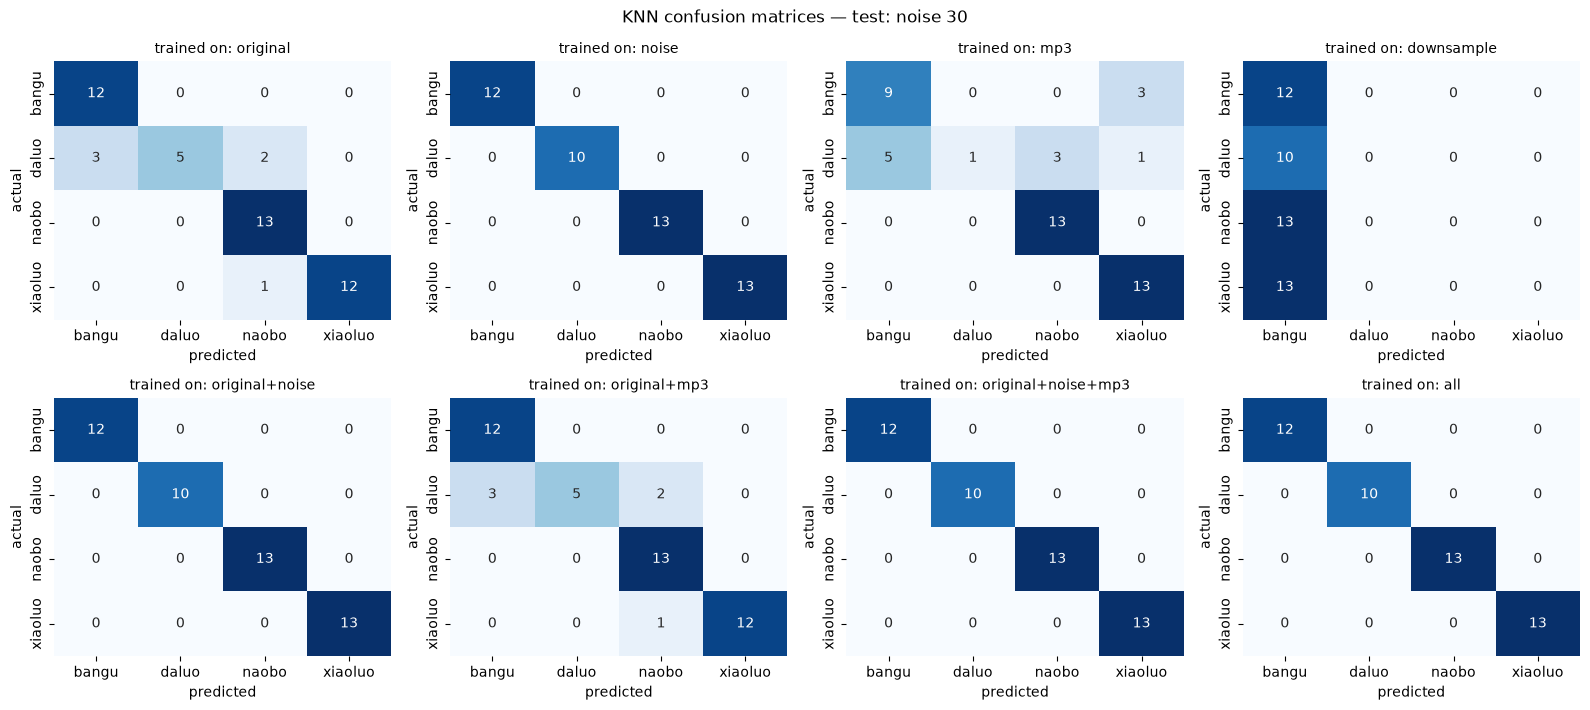

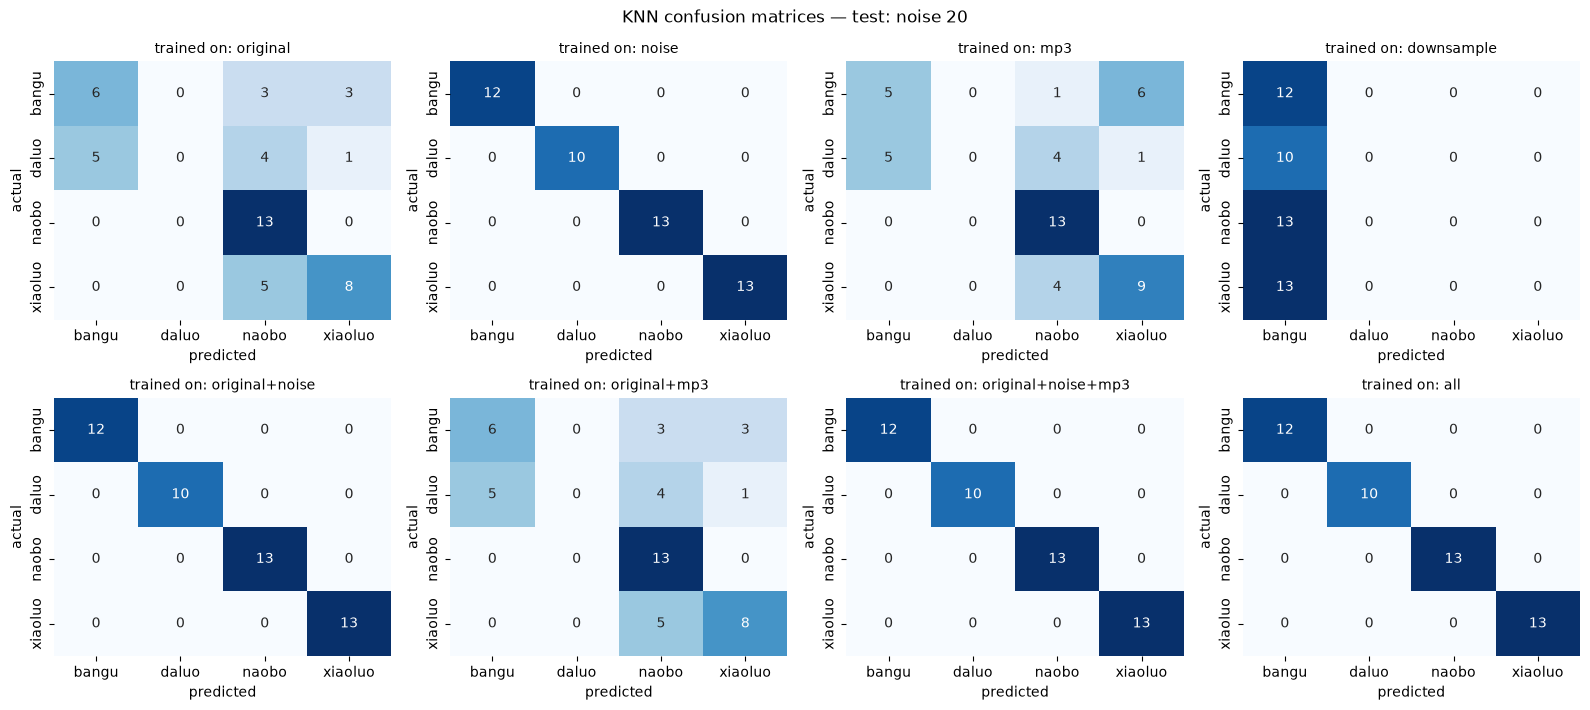

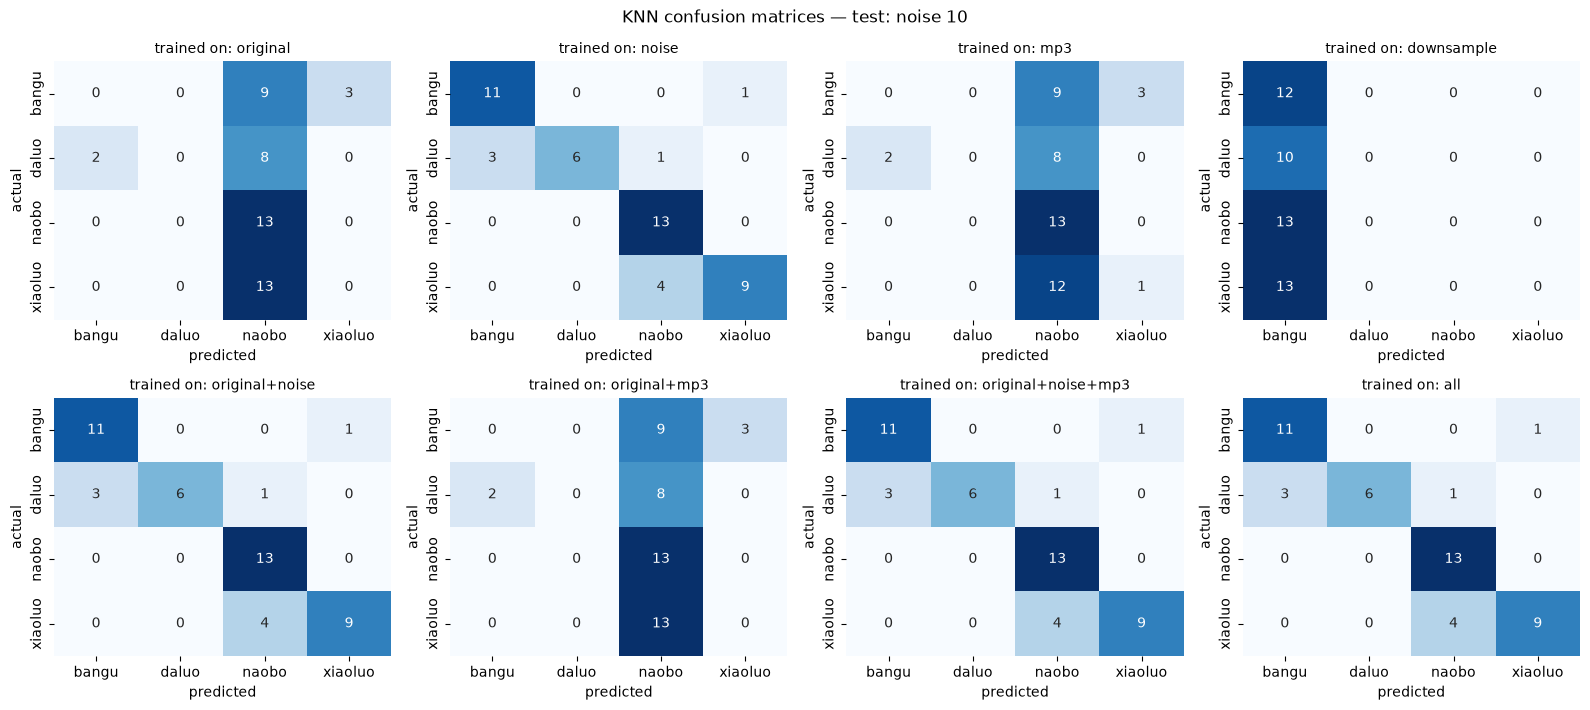

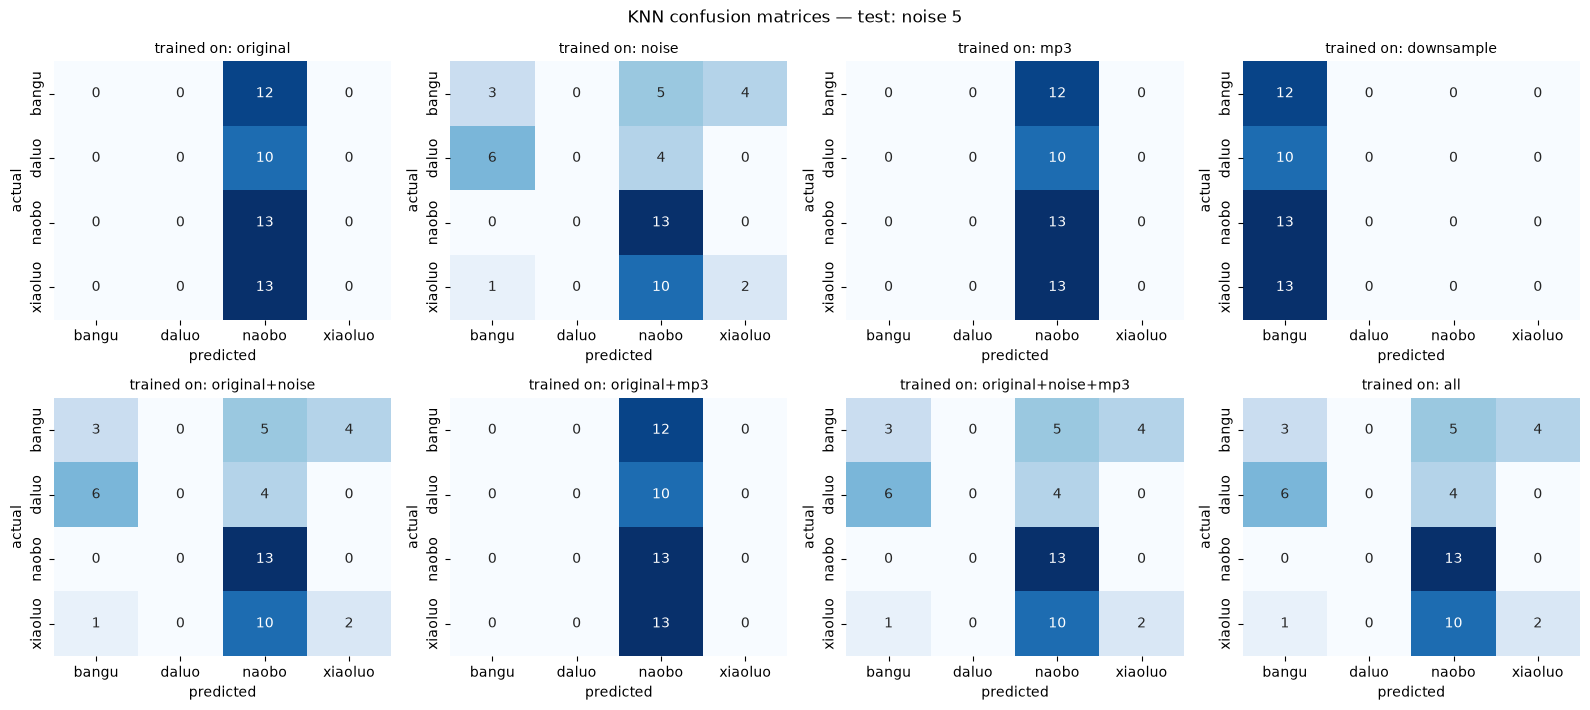

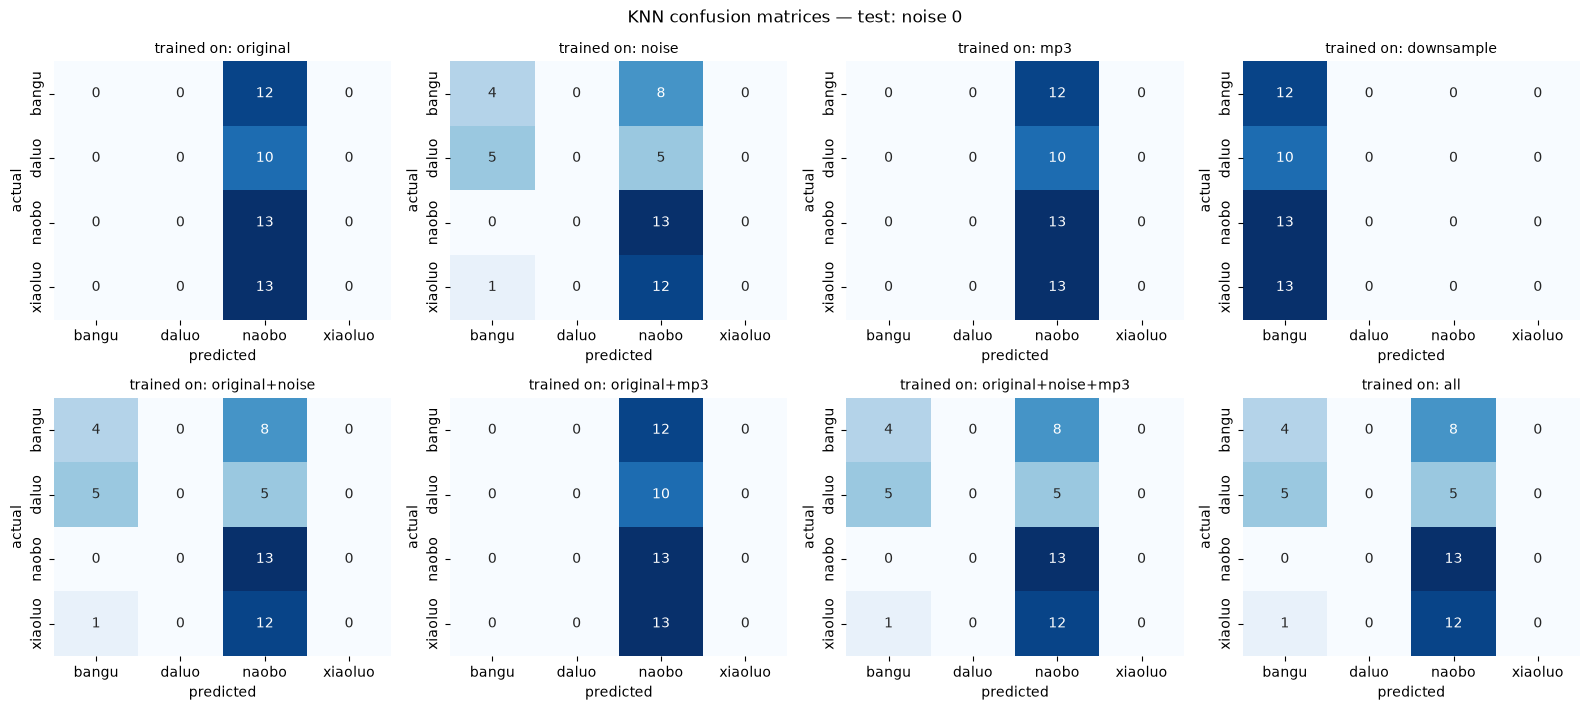

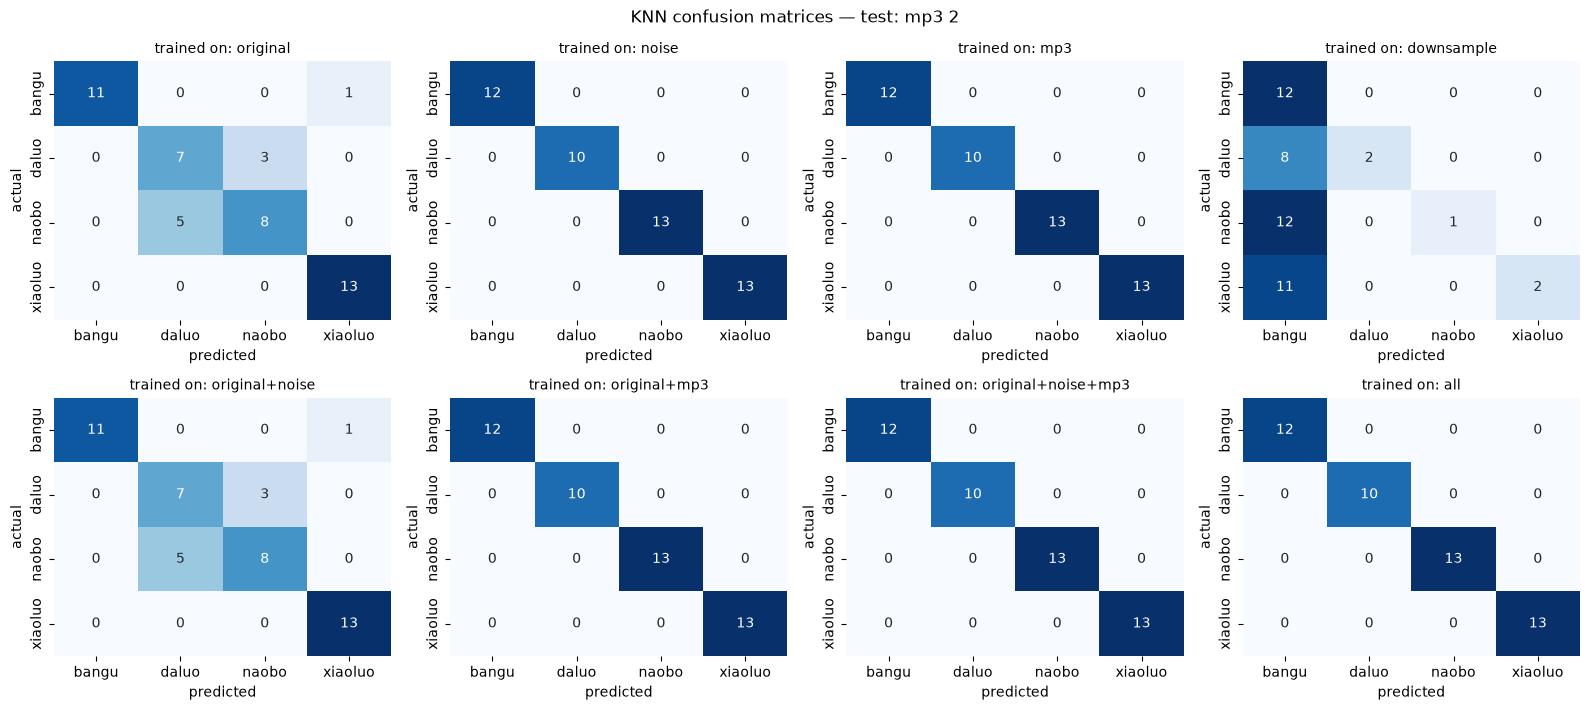

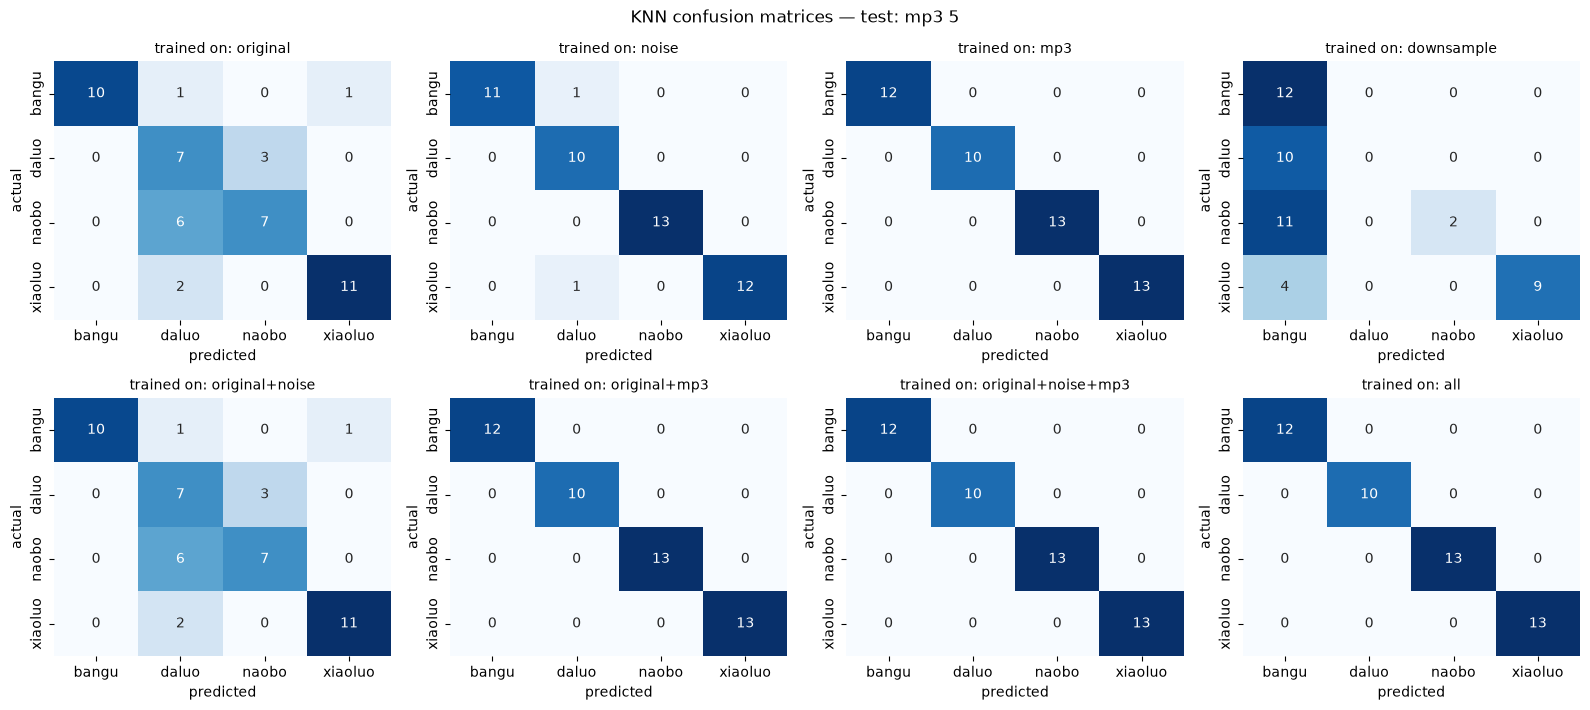

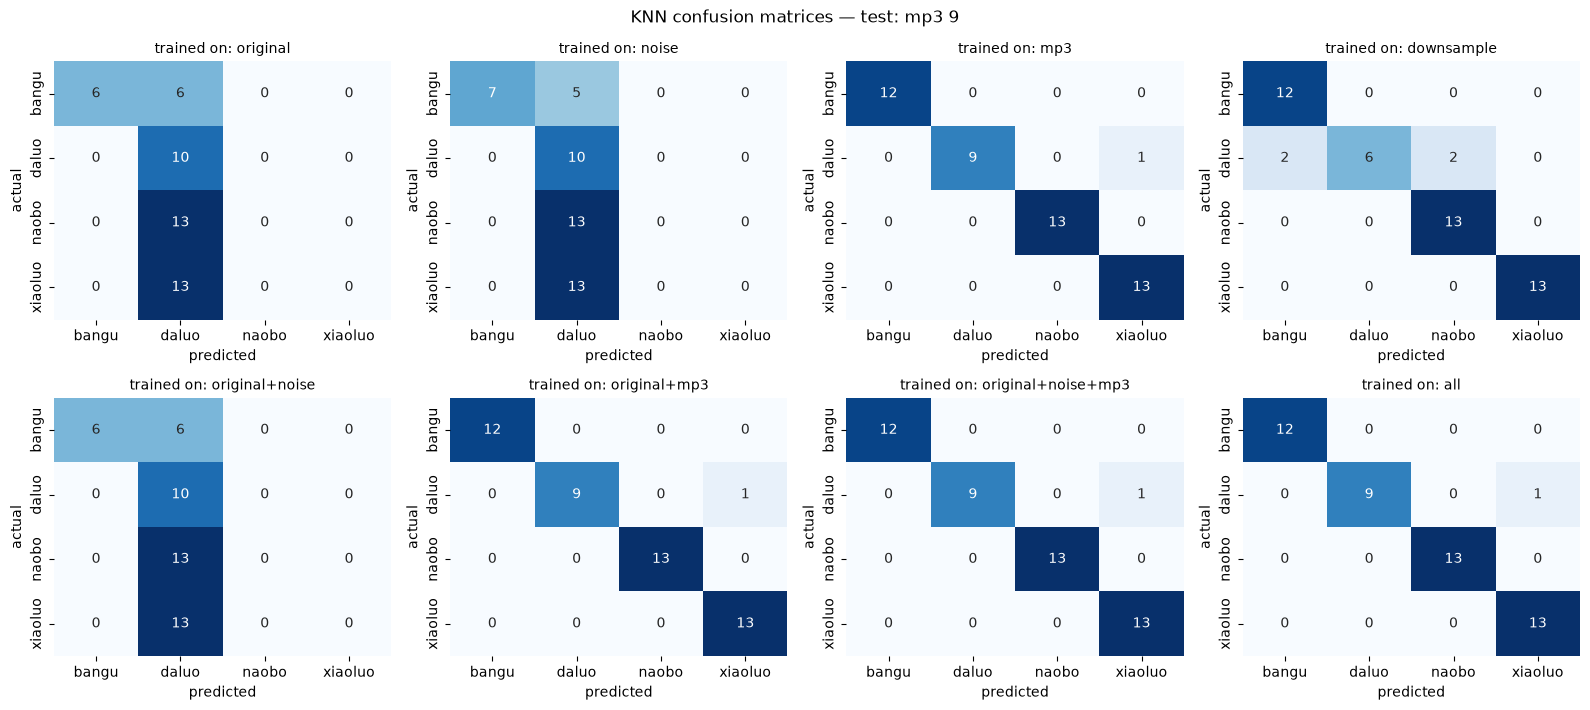

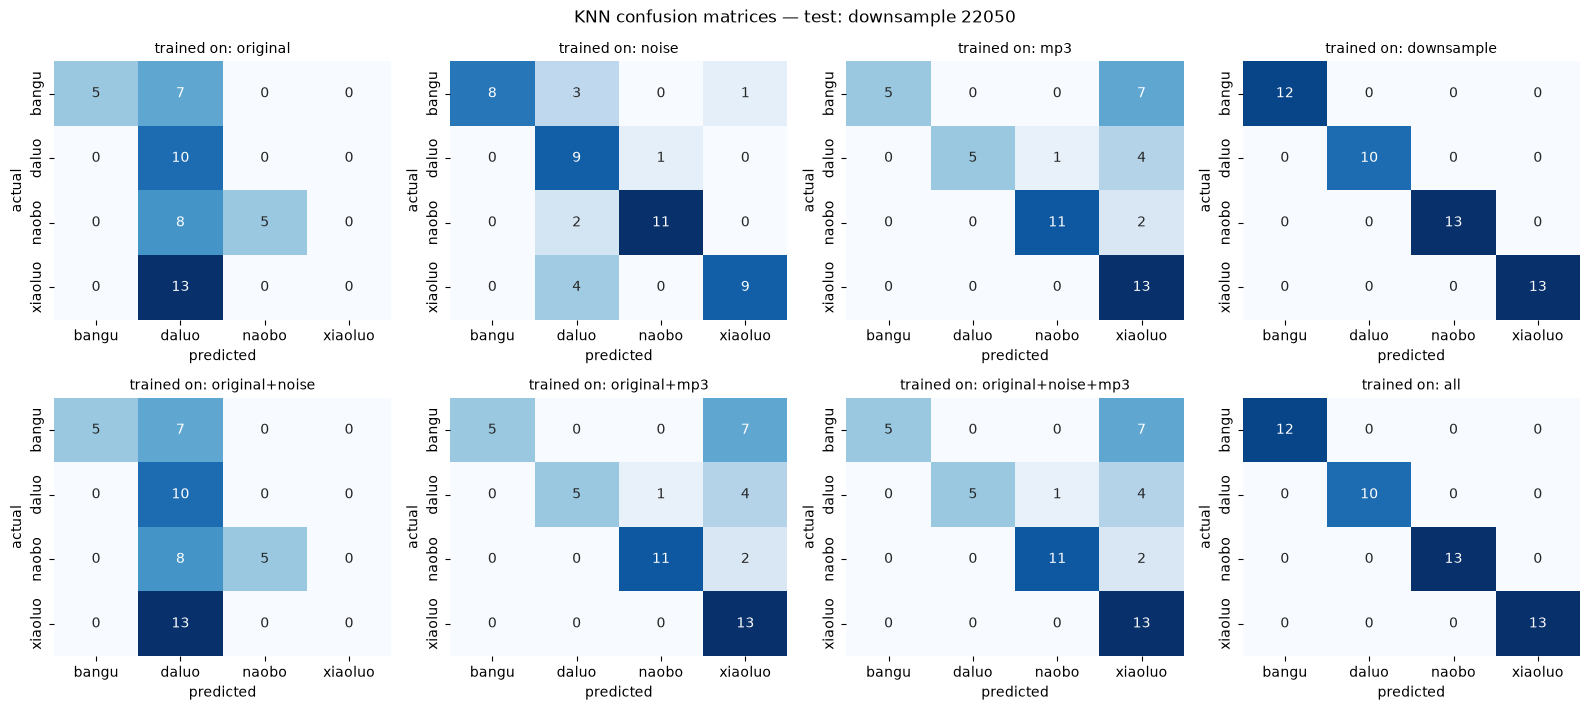

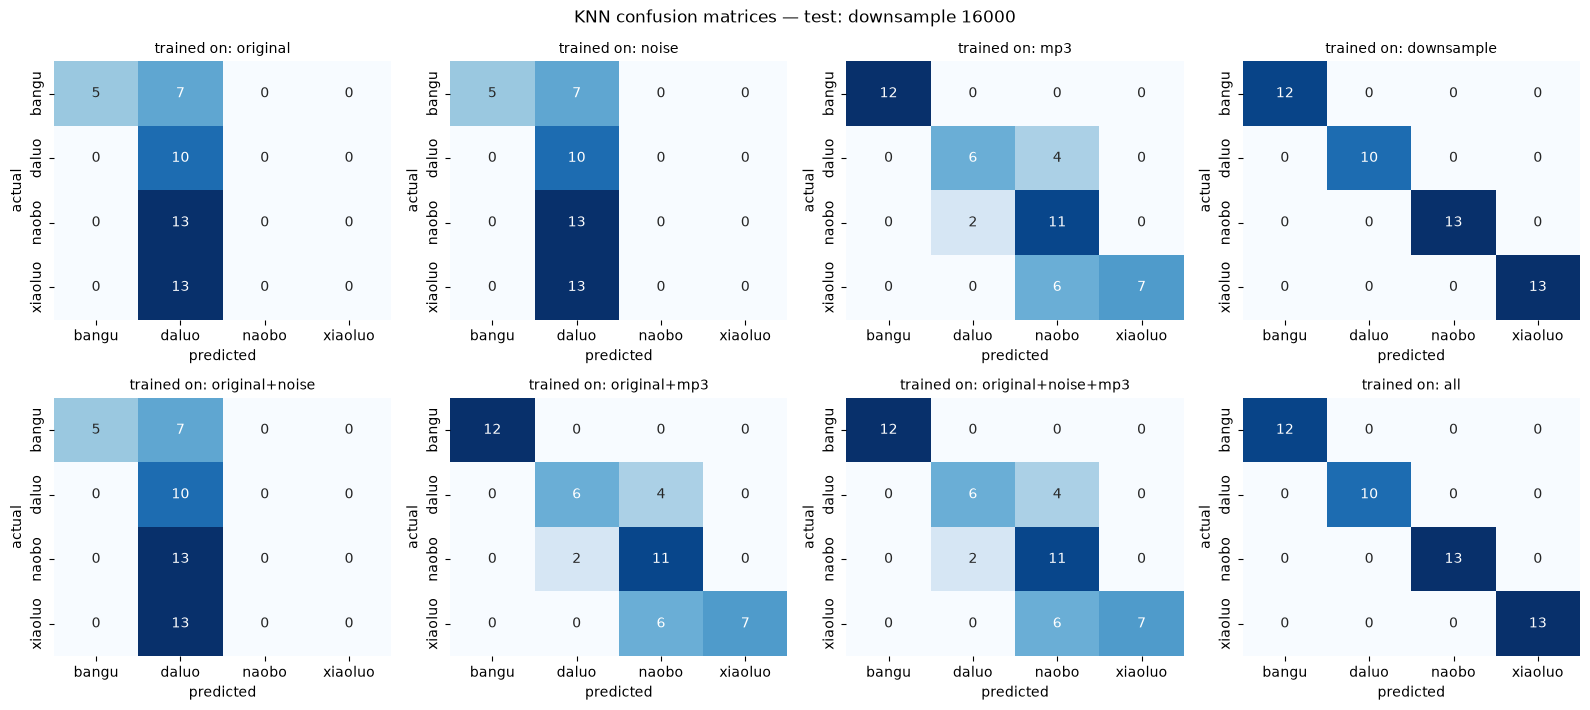

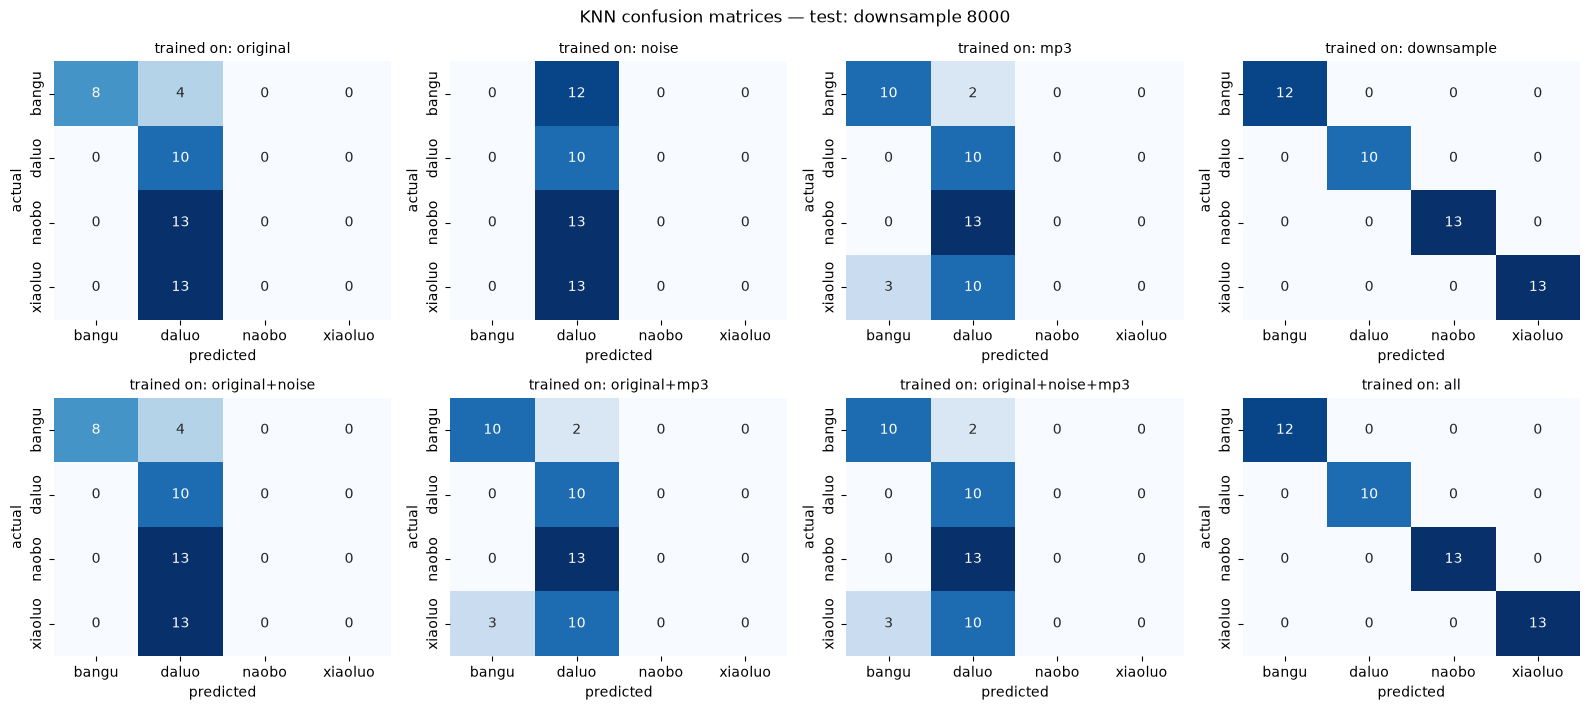

In [12]:
svm_models = {scenario: load_model(scenario + "_svm") for scenario in scenarios}
knn_models = {scenario: load_model(scenario + "_knn") for scenario in scenarios}

# Evaluate every model on every test set and level
svm_results, svm_matrices = evaluate_models(svm_models, testing, "SVM")
knn_results, knn_matrices = evaluate_models(knn_models, testing, "KNN")
results = pd.concat([svm_results, knn_results], ignore_index=True)
matrices = {**svm_matrices, **knn_matrices}

# Store
results_dir = Path("pipeline_output/results")
results_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(results_dir / "results.csv", index=False)
pd.to_pickle(matrices, results_dir / "confusion_matrices.pkl")

for model_name in ("SVM", "KNN"):
    display(Markdown(f"## {model_name}"))
    show_table(model_name, "macro_f1", results)
    show_table(model_name, "accuracy", results)

    plot_robustness(results, model_name, "macro_f1")
    plot_robustness(results, model_name, "accuracy")
    plt.show()
    
    show_confusion_grid(matrices, model_name, "original")       # clean test clips
    
    for snr in TEST_SNR:
        show_confusion_grid(matrices, model_name, "noise", snr)       # noise test clips
    for q in TEST_COMPRESSION:
        show_confusion_grid(matrices, model_name, "mp3", q) # mp3 test clips
    for sr in DOWN_SR:
        show_confusion_grid(matrices, model_name, "downsample", sr) # downsample test clips